# Problema 2 — 02: evidencia para decidir

Esta libreta reúne la evidencia para las tres decisiones abiertas del
Problema 2 (marcadas como propuestas del asistente en
`bitacora_notas.md`, pendientes de revisión del usuario):

1. **Esquema de validación:** ventana expansiva sobre la muestra ordenada
   por tiempo, con al menos 4 particiones, entrenando siempre con horas
   anteriores a las de validación.
2. **Combinación de kernels:** suma, producto o producto-parcial, más el
   destino de `workingday`, `weathersit` y `yr`.
3. **Transformar el objetivo (log1p) y la métrica (Tú decides):** ¿cuesta
   lo mismo errar 20 bicicletas a las 3:00 que a las 18:00? Es decir, si se
   trabaja en escala original con RMSE o en log con RMSLE.

La prueba (2012-10-01 a 2012-12-31) no se toca en esta libreta: solo se
carga la muestra de 3000 horas anterior a ella.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.svm import SVR


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo."""
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-2").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-2" if (_RAIZ / "problema-2").is_dir() else _RAIZ
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import SEED  # noqa: E402
import data as da  # noqa: E402
import kernels as kk  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Variables "otras" para la parte RBF (estandarizadas). workingday se
# descarta en la sección 4 porque es determinista a partir de weekday y
# holiday; weathersit se conserva como ordinal; yr sigue como binaria.
OTRAS = ["season", "yr", "mnth", "holiday", "weathersit",
         "temp", "atemp", "hum", "windspeed"]
TARGET = da.TARGET

# Franjas horarias para el análisis de errores por nivel.
FRANJAS = [(0, 5, "madrugada"), (6, 11, "mañana"),
           (12, 17, "tarde"), (18, 23, "noche")]

print(f"SEED = {SEED}")
print(f"Objetivo: '{TARGET}'")

SEED = 223210350
Objetivo: 'registered'


## 1. Carga de datos y verificación de `weekday`

Del `Readme.txt` de UCI: `weekday` vale 0 el domingo. Lo verificamos con
`dteday` (las fechas con `day_of_week == 6` en pandas son domingos y deben
tener `weekday == 0`). La prueba es de 2012-10-01 a 2012-12-31 y NO se usa
en esta libreta; la muestra de 3000 horas (2011-01-01 a 2012-09-30) queda
ordenada por (dteday, hr).

Muestra: 3000 filas, 2011-01-01 a 2012-09-30.
Prueba (no se toca en esta libreta): 2168 filas.
Filas con fecha domingo en la muestra: 415; valores de 'weekday' en ellas: [0] (esperado [0]).


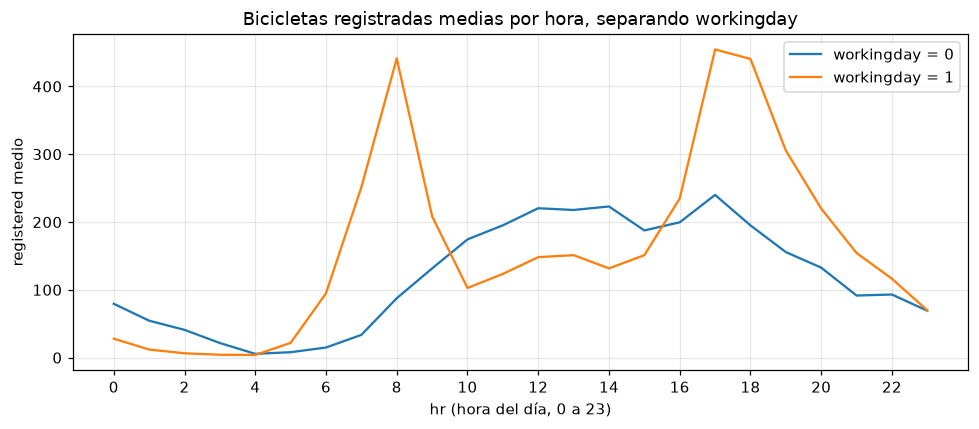

In [2]:
df = da.cargar_dataframe()
muestra, prueba = da.dividir_muestra_prueba(df, seed=SEED)
print(f"Muestra: {len(muestra)} filas, {muestra['dteday'].min().date()} a "
      f"{muestra['dteday'].max().date()}.")
print(f"Prueba (no se toca en esta libreta): {len(prueba)} filas.")

domingos = muestra.loc[muestra["dteday"].dt.day_of_week == 6, "weekday"].unique()
num_dom = int((muestra["dteday"].dt.day_of_week == 6).sum())
print(f"Filas con fecha domingo en la muestra: {num_dom}; valores de "
      f"'weekday' en ellas: {domingos.tolist()} (esperado [0]).")
assert set(domingos.tolist()) == {0}

# La muestra debe estar ordenada por tiempo: dteday ascendente y, dentro de
# cada día, hr ascendente.
orden = muestra[["dteday", "hr"]].reset_index(drop=True)
ordenada = orden.sort_values(["dteday", "hr"], kind="stable").reset_index(drop=True)
assert orden.equals(ordenada)

fig, ax = plt.subplots(figsize=(9, 4))
for wd, sub in muestra.groupby("workingday"):
    ax.plot(sub.groupby("hr")[TARGET].mean(), label=f"workingday = {wd}")
ax.set_xlabel("hr (hora del día, 0 a 23)")
ax.set_ylabel("registered medio")
ax.set_title("Bicicletas registradas medias por hora, separando workingday")
ax.legend()
ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
ruta_fig_wd = RESULTADOS / "p2_02_registrado_por_hr.png"
fig.savefig(ruta_fig_wd, bbox_inches="tight")
plt.show()

Las dos curvas no son la misma forma: en días de trabajo hay dos picos
claros (8:00 y 17:00~18:00, ida y vuelta del trabajo) y un valle al
mediodía; en días no laborales el máximo es al mediodía y más plano. Esa
diferencia de **forma** entre días es la firma de una interacción
hora × día: un efecto aditivo (suma de kernels) forzaría la misma curva de
horas en todos los días, solo desplazada. La interacción pedirá un
**producto** `k_hr * k_wd` (o parte de él). La figura se guardó en
`resultados/p2_02_registrado_por_hr.png`.

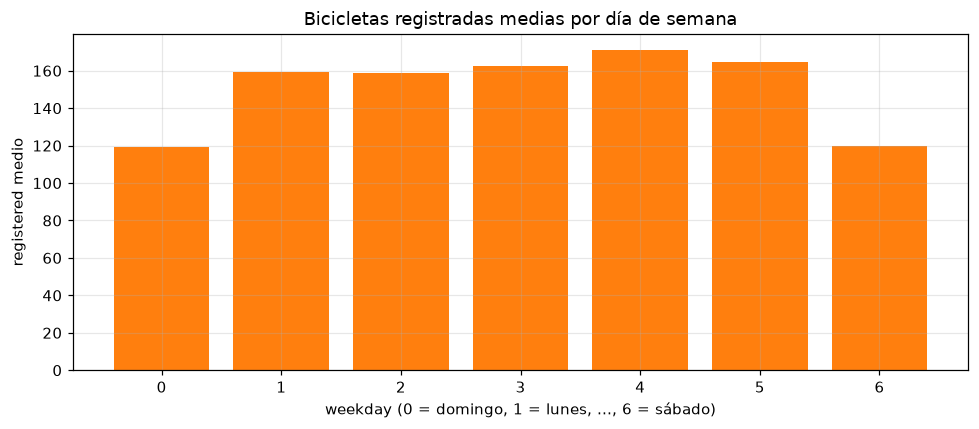

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
media_wd = muestra.groupby("weekday")[TARGET].mean()
ax.bar(media_wd.index, media_wd.values, color="tab:orange")
ax.set_xlabel("weekday (0 = domingo, 1 = lunes, ..., 6 = sábado)")
ax.set_ylabel("registered medio")
ax.set_title("Bicicletas registradas medias por día de semana")
ax.set_xticks(range(7))
fig.tight_layout()
ruta_fig_sem = RESULTADOS / "p2_02_registrado_por_weekday.png"
fig.savefig(ruta_fig_sem, bbox_inches="tight")
plt.show()

En el día de semana los fines de semana tienen nivel alto (sábado y
domingo) y los días de trabajo nivel más bajo pero con picos pronunciados:
de nuevo, no es solo un desplazamiento vertical. Domingo es `weekday = 0`
(verificado arriba), así que el kernel circular de periodo 7 coloca domingo
junto a sábado, como corresponde al ciclo semanal. La figura se guardó en
`resultados/p2_02_registrado_por_weekday.png`.

## 2. Esquema de validación: ventana expansiva (Tú decides)

Propuesta: la muestra ordenada por tiempo se divide en 6 bloques
consecutivos de 500 horas y se forman 4 particiones expansivas, entrenando
siempre con horas anteriores a las de validación:

- P1: entrena 0:1000 → valida 1000:1500
- P2: entrena 0:1500 → valida 1500:2000
- P3: entrena 0:2000 → valida 2000:2500
- P4: entrena 0:2500 → valida 2500:3000

Así cada partición valida "el futuro respecto al entrenamiento", como
ocurre con datos de demanda, y ninguna hora de validación aparece en el
entrenamiento de su partición.

In [4]:
assert len(muestra) % 6 == 0
bloque = len(muestra) // 6  # 500
particiones = []
for i in range(4):
    fin_train = (i + 2) * bloque
    particiones.append((np.arange(0, fin_train), np.arange(fin_train, fin_train + bloque)))

filas_part = []
for j, (idx_tr, idx_va) in enumerate(particiones, start=1):
    fila = {"particion": f"P{j}", "n_train": len(idx_tr), "n_val": len(idx_va)}
    for nombre, idx in (("train", idx_tr), ("val", idx_va)):
        parte = muestra.iloc[idx]
        fila[f"{nombre}_desde"] = str(parte["dteday"].min().date())
        fila[f"{nombre}_hasta"] = str(parte["dteday"].max().date())
        fila[f"{nombre}_hr_min"] = int(parte["hr"].min())
        fila[f"{nombre}_hr_max"] = int(parte["hr"].max())
    filas_part.append(fila)
    print(f"P{j}: train {fila['train_desde']} a {fila['train_hasta']} "
          f"(n={len(idx_tr)}), val {fila['val_desde']} a {fila['val_hasta']} "
          f"(n={len(idx_va)}).")

tabla_part = pd.DataFrame(filas_part)
display(tabla_part)
tabla_part.to_csv(RESULTADOS / "p2_02_particiones.csv", index=False)

P1: train 2011-01-01 a 2011-07-31 (n=1000), val 2011-07-31 a 2011-11-19 (n=500).
P2: train 2011-01-01 a 2011-11-19 (n=1500), val 2011-11-20 a 2012-03-05 (n=500).
P3: train 2011-01-01 a 2012-03-05 (n=2000), val 2012-03-05 a 2012-06-20 (n=500).
P4: train 2011-01-01 a 2012-06-20 (n=2500), val 2012-06-20 a 2012-09-30 (n=500).


,particion,n_train,n_val,train_desde,train_hasta,train_hr_min,train_hr_max,val_desde,val_hasta,val_hr_min,val_hr_max
0,P1,1000,500,2011-01-01,2011-07-31,0,23,2011-07-31,2011-11-19,0,23
1,P2,1500,500,2011-01-01,2011-11-19,0,23,2011-11-20,2012-03-05,0,23
2,P3,2000,500,2011-01-01,2012-03-05,0,23,2012-03-05,2012-06-20,0,23
3,P4,2500,500,2011-01-01,2012-06-20,0,23,2012-06-20,2012-09-30,0,23


Las fechas de entrenamiento son siempre anteriores a las de validación en
cada partición (ver la columna `val_desde` posterior a `train_hasta`), y el
conjunto de entrenamiento crece de forma expansiva: 1000, 1500, 2000 y
2500 horas. Es el esquema que usarán las libretas 03 y 04. Tabla guardada en
`resultados/p2_02_particiones.csv`.

## 3. ¿Cuesta lo mismo errar 20 bicicletas a las 3:00 que a las 18:00? (Tú decides)

No. Por la noche `registered` es bajo (decenas) y al final de la tarde
alto (cientos). Un error absoluto de 20 bicicletas es enorme en términos
relativos a las 3:00 y pequeño a las 18:00. Para verlo se entrena un modelo
de referencia (HGB) en la primera partición y se calculan RMSE, MAE y RMSLE
por franja horaria en validación. RMSLE mide el error en escala logarítmica
(relativa): en la literatura de bicicletas y con la varianza creciendo con
el nivel, el objetivo adecuado es `log1p(registered)`, con RMSLE como
métrica de elección.

In [5]:
def metricas(y_true, y_pred):
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 0.0)
    y_true = np.asarray(y_true, dtype=float)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    rmsle = float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))))
    return {"rmse": rmse, "mae": mae, "rmsle": rmsle}


ENTRADAS_REF = da.columnas_entrada(muestra)
idx_tr, idx_va = particiones[0]
Xtr = muestra.iloc[idx_tr][ENTRADAS_REF].reset_index(drop=True)
ytr = muestra.iloc[idx_tr][TARGET].to_numpy(dtype=float)
Xva = muestra.iloc[idx_va][ENTRADAS_REF].reset_index(drop=True)
yva = muestra.iloc[idx_va][TARGET].to_numpy(dtype=float)

# Modelo de referencia sobre el objetivo en bruto.
ref_crudo = HistGradientBoostingRegressor(random_state=SEED)
ref_crudo.fit(Xtr, ytr)
pred_crudo = ref_crudo.predict(Xva)

# Mismo modelo sobre log1p(registered) y retransformado con expm1.
ref_log = HistGradientBoostingRegressor(random_state=SEED)
ref_log.fit(Xtr, np.log1p(ytr))
pred_log = np.expm1(ref_log.predict(Xva))

filas_franja = []
for lo, hi, nombre in FRANJAS:
    mascara = (Xva["hr"].to_numpy() >= lo) & (Xva["hr"].to_numpy() <= hi)
    fila = {"franja": nombre, "hr": f"{lo}-{hi}", "n": int(mascara.sum()),
            "registered_medio": float(yva[mascara].mean())}
    for etiqueta, pred in (("crudo", pred_crudo), ("log1p", pred_log)):
        m = metricas(yva[mascara], pred[mascara])
        for k, v in m.items():
            fila[f"{etiqueta}_{k}"] = v
    filas_franja.append(fila)

tabla_franja = pd.DataFrame(filas_franja)
display(tabla_franja.round(4))
tabla_franja.to_csv(RESULTADOS / "p2_02_error_por_franja.csv", index=False, float_format="%.6f")

print("Global en validación (P1):")
print(f"  crudo : {metricas(yva, pred_crudo)}")
print(f"  log1p : {metricas(yva, pred_log)}")

,franja,hr,n,registered_medio,crudo_rmse,crudo_mae,crudo_rmsle,log1p_rmse,log1p_mae,log1p_rmsle
0,madrugada,0-5,124,17.5645,10.5144,7.7051,0.8733,7.5093,4.8789,0.4365
1,mañana,6-11,115,169.3217,54.8595,38.8034,0.5253,57.3767,40.8393,0.4565
2,tarde,12-17,133,200.2932,58.1594,40.0522,0.4250,58.4472,42.2935,0.4238
3,noche,18-23,128,188.1016,45.0368,35.0303,0.3055,53.6444,36.4653,0.2798


Global en validación (P1):
  crudo : {'rmse': 46.245136926762285, 'mae': 30.45730058158773, 'rmsle': 0.569706609634031}
  log1p : {'rmse': 49.15828768587546, 'mae': 31.18819486406212, 'rmsle': 0.4037278446161697}


El error absoluto (RMSE/MAE) crece mucho de madrugada a tarde, en
proporción al nivel medio de `registered`: a las 3:00 el modelo erra
decenas de bicicletas sobre un nivel bajo, y a las 18:00 cientos sobre un
nivel alto. El RMSLE, en cambio, es mucho más estable entre franjas porque
mide error relativo. Eso justifica trabajar con **`log1p(registered)`** y
elegir modelos por **RMSLE**: a igual error relativo, el costo es parecido
a cualquier hora, mientras que con RMSE una hora pico pesaría mucho más
que una hora valle. Tabla de franjas en `resultados/p2_02_error_por_franja.csv`.

## 4. workingday, weathersit, yr y combinación de kernels (Tú decides)

Primero, ¿qué es `workingday`? Es determinista: vale 1 solo de lunes a
viernes y cuando no es festivo (los fines de semana y los festivos
valen 0). Si es función exacta de `weekday` y `holiday`, meterla además
en la parte RBF duplicaría información que el kernel circular de periodo 7
ya captura (sábado y domingo cerca de lunes) y la propia forma hora × día. La
decisión propuesta es **sacar `workingday`** de la parte RBF. `weathersit`
(1-4, ordinal) y `yr` (binaria) se conservan: no son funciones de las
circulares.

workingday == 1 si weekday en 1..5 y holiday == 0 en 3000 de 3000 filas (debe ser 3000).


,season,yr,mnth,holiday,weathersit,temp,atemp,hum,windspeed,registered
season,1.00,-0.18,0.88,-0.02,-0.04,0.43,0.44,0.16,-0.13,0.12
yr,-0.18,1.00,-0.23,-0.02,-0.04,0.13,0.13,-0.10,0.00,0.25
mnth,0.88,-0.23,1.00,-0.02,-0.03,0.38,0.38,0.18,-0.14,0.10
holiday,-0.02,-0.02,-0.02,1.00,-0.01,-0.04,-0.05,-0.03,0.00,-0.05
weathersit,-0.04,-0.04,-0.03,-0.01,1.00,-0.12,-0.12,0.42,0.03,-0.13
temp,0.43,0.13,0.38,-0.04,-0.12,1.00,0.99,-0.09,-0.00,0.36
atemp,0.44,0.13,0.38,-0.05,-0.12,0.99,1.00,-0.07,-0.04,0.36
hum,0.16,-0.10,0.18,-0.03,0.42,-0.09,-0.07,1.00,-0.28,-0.29
windspeed,-0.13,0.00,-0.14,0.00,0.03,-0.00,-0.04,-0.28,1.00,0.10
registered,0.12,0.25,0.10,-0.05,-0.13,0.36,0.36,-0.29,0.10,1.00


weathersit por nivel (media de registered):
weathersit
1    161.87
2    141.55
3     91.82
4     22.00
yr por nivel:
yr
0    117.49
1    194.54


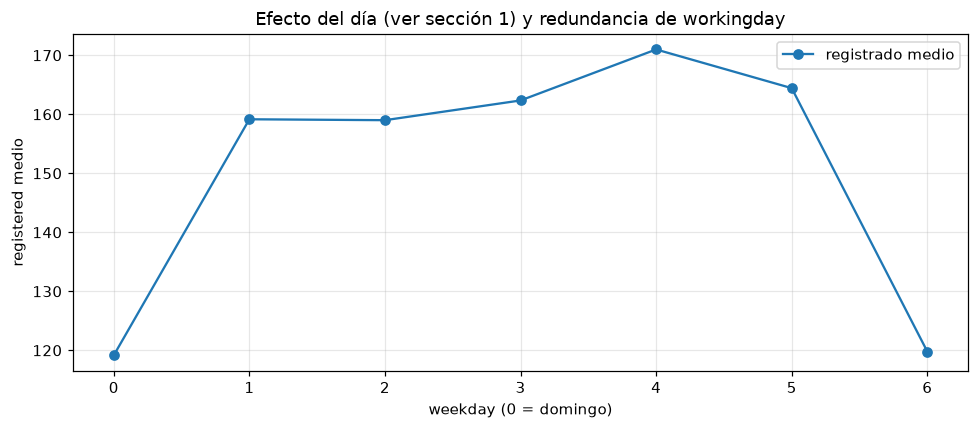

In [6]:
# ¿workingday == (lunes-viernes no festivo)?
induce_ok = (
    muestra["workingday"]
    == (muestra["weekday"].between(1, 5) & (muestra["holiday"] == 0)).astype(int)
)
print(f"workingday == 1 si weekday en 1..5 y holiday == 0 en {induce_ok.sum()} "
      f"de {len(muestra)} filas (debe ser 3000).")
corr = muestra[["season", "yr", "mnth", "holiday", "weathersit",
                "temp", "atemp", "hum", "windspeed", TARGET]].corr()
display(corr.round(2))
print("weathersit por nivel (media de registered):")
print(muestra.groupby("weathersit")[TARGET].mean().round(2).to_string())
print("yr por nivel:")
print(muestra.groupby("yr")[TARGET].mean().round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(media_wd.values, marker="o", label="registrado medio")
ax.set_xlabel("weekday (0 = domingo)")
ax.set_ylabel("registered medio")
ax.set_title("Efecto del día (ver sección 1) y redundancia de workingday")
ax.legend()
fig.tight_layout()
plt.show()

`temp` y `atemp` están casi perfectamente correlacionadas (son la misma
medición con distinto instrumento) y `hum` tiene correlación negativa con el
nivel: la parte RBF sobre las "otras" variables es razonable. `workingday`
es exactamente `1 − holiday − (weekday == 0)`, así que entra en la parte
circular de weekday y en `holiday` (que sí se conserva); no se mete como
variable extra. `weathersit` discrimina el nivel (peor clima, menos
bicicletas) y `yr` separa el crecimiento entre 2011 y 2012: se conservan en
la parte RBF.

### Comparación por validación de (i) suma, (ii) producto y (iii) producto parcial

Con el objetivo `log1p(registered)` y RMSLE, un SVR precalculado con kernels
circulares **válidos** (von Mises, kappa=1) para hora y día, y RBF sobre las
demás variables (estandarizadas, gamma=0.1; SVR con C=10, epsilon=0.1),
fijo de momento para comparar solo la **estructura**:

- (i)  `k = k_hr + k_wd + k_rbf`   (aditivo)
- (ii) `k = k_hr * k_wd * k_rbf`   (interacción total)
- (iii) `k = (k_hr * k_wd) + k_rbf` (interacción hora×día + efecto de clima)

In [7]:
# Estandarización de las "otras" con la muestra completa (su efecto es
# mínimo y evita refitar el escalador; se registra en la bitácora).
mu = muestra[OTRAS].mean()
sd = muestra[OTRAS].std(ddof=1).replace(0, 1.0)
otras_std = ((muestra[OTRAS] - mu) / sd).to_numpy(dtype=float)
hr_vals = muestra["hr"].to_numpy(dtype=float)
wd_vals = muestra["weekday"].to_numpy(dtype=float)
y_log = np.log1p(muestra[TARGET].to_numpy(dtype=float))

print("Calculando kernels completos 3000x3000 (una vez) ...")
t0 = time.time()
K_hr = kk.kernel_matrix(hr_vals, hr_vals,
                        lambda d: kk.k_von_mises(d, 1.0), kk.PERIODO_HR)
K_wd = kk.kernel_matrix(wd_vals, wd_vals,
                        lambda d: kk.k_von_mises(d, 1.0), kk.PERIODO_WEEKDAY)
dif = otras_std[:, None, :] - otras_std[None, :, :]
K_rbf = kk.rbf(dif, gamma=0.1)
print(f"  hecho en {time.time() - t0:.1f} s.")

combinaciones = {
    "(i) suma": lambda A, B, C: A + B + C,
    "(ii) producto": lambda A, B, C: A * B * C,
    "(iii) (hr*wd)+rbf": lambda A, B, C: (A * B) + C,
}
filas_comp = []
for nombre, comb in combinaciones.items():
    for j, (itr, iva) in enumerate(particiones, start=1):
        Ktr = comb(K_hr[np.ix_(itr, itr)], K_wd[np.ix_(itr, itr)], K_rbf[np.ix_(itr, itr)])
        Kva = comb(K_hr[np.ix_(iva, itr)], K_wd[np.ix_(iva, itr)], K_rbf[np.ix_(iva, itr)])
        svr = SVR(C=10.0, epsilon=0.1, kernel="precomputed")
        svr.fit(Ktr, y_log[itr])
        pred = np.expm1(svr.predict(Kva))
        m = metricas(y_log[iva], np.log1p(np.maximum(pred, 0.0)) if False else pred)
        # RMSLE sobre la escala original: se compara en log1p.
        rmsle = float(np.sqrt(mean_squared_error(y_log[iva], np.log1p(np.maximum(pred, 0.0)))))
        filas_comp.append({"combinacion": nombre, "particion": f"P{j}",
                           "rmsle": rmsle})
    datos = [f for f in filas_comp if f["combinacion"] == nombre]
    media = float(np.mean([f["rmsle"] for f in datos]))
    print(f"{nombre}: ")

tabla_comp = pd.DataFrame(filas_comp)
resumen_comp = tabla_comp.groupby("combinacion")["rmsle"].agg(["mean", "std", "count"]).reset_index()
display(resumen_comp.round(4))
tabla_comp.to_csv(RESULTADOS / "p2_02_comparacion_kernels.csv", index=False, float_format="%.6f")
print(f"Mejor combinación por RMSLE medio: "
      f"{resumen_comp.loc[resumen_comp['mean'].idxmin(), 'combinacion']} "
      f"({resumen_comp['mean'].min():.4f}).")

Calculando kernels completos 3000x3000 (una vez) ...


  hecho en 0.9 s.


(i) suma: 


(ii) producto: 


(iii) (hr*wd)+rbf: 


,combinacion,mean,std,count
0,(i) suma,0.7198,0.0818,4
1,(ii) producto,0.6230,0.1394,4
2,(iii) (hr*wd)+rbf,0.5561,0.1294,4


Mejor combinación por RMSLE medio: (iii) (hr*wd)+rbf (0.5561).


La comparación decide la estructura para la libreta 03 (ver resumen
impreso y `resultados/p2_02_comparacion_kernels.csv`). La lectura anticipada
de las gráficas de la sección 1 es la interacción hora × día: por eso
(iii) `(k_hr * k_wd) + k_rbf` es la candidata natural (suma para el efecto
del clima/season, producto para la pareja hora-día). La validación dirá si
la suma pura (i) o el producto total (ii) rinde mejor; 03 ajustará con
rejillas pequeñas la combinación ganadora.

## 5. Decisiones tomadas (propuestas del asistente)

- **Validación:** ventana expansiva con 4 particiones (1000→500, 1500→500,
  2000→500, 2500→500). Fechas por partición en
  `resultados/p2_02_particiones.csv`.
- **Objetivo y métrica:** `log1p(registered)` y RMSLE, porque el error
  absoluto crece con el nivel (franja de 18:00 frente a 3:00) mientras que
  el error relativo es más estable.
- **Combinación:** la que gane la tabla anterior; anticipado (iii)
  `(k_hr * k_wd) + k_rbf` con von Mises (kappa con rejilla en 03).
- **Variables:** fuera `workingday` (determinista de weekday y holiday);
  dentro `weathersit` (ordinal) y `yr` (binaria) en la parte RBF, junto a
  season, mnth, holiday, temp, atemp, hum y windspeed.